# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 106.6 KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: <StringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


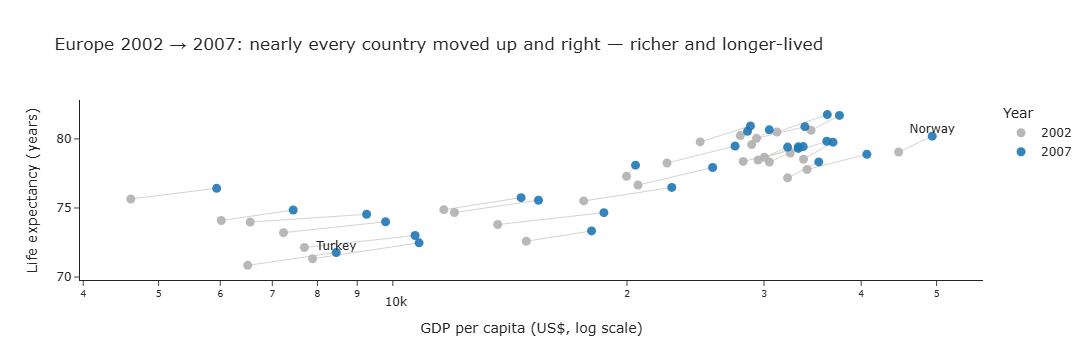

In [3]:
# Task 1 — Europe, 2002 vs 2007
europe = df.loc[(df['continent'] == 'Europe') & (df['year'].isin([2002, 2007]))].copy()
europe['year'] = europe['year'].astype(str)  # categorical -> discrete colours

fig1 = px.scatter(
    europe,
    x='gdpPercap',
    y='lifeExp',
    color='year',
    color_discrete_map={'2002': '#b0b0b0', '2007': '#1f77b4'},  # grey = before, blue = after
    category_orders={'year': ['2002', '2007']},
    hover_name='country',
    log_x=True,
    labels={'gdpPercap': 'GDP per capita (US$, log scale)',
            'lifeExp': 'Life expectancy (years)',
            'year': 'Year'},
    title='Europe 2002 → 2007: nearly every country moved up and right — richer and longer-lived',
)
fig1.update_traces(marker=dict(size=9, opacity=0.9))

# Connector lines from each country's 2002 point to its 2007 point (shows direction of change)
wide = europe.pivot(index='country', columns='year', values=['gdpPercap', 'lifeExp'])
lx, ly = [], []
for country, row in wide.iterrows():
    lx += [row[('gdpPercap', '2002')], row[('gdpPercap', '2007')], None]
    ly += [row[('lifeExp', '2002')], row[('lifeExp', '2007')], None]
lines = go.Scatter(x=lx, y=ly, mode='lines', line=dict(color='lightgrey', width=1),
                   hoverinfo='skip', showlegend=False)
fig1.add_trace(lines)
fig1.data = fig1.data[-1:] + fig1.data[:-1]  # draw lines underneath the markers

# Label notable points directly (2007 positions): lowest life expectancy and richest country
e07 = europe[europe['year'] == '2007']
notable = pd.concat([e07.nsmallest(1, 'lifeExp'), e07.nlargest(1, 'gdpPercap')])
fig1.add_trace(go.Scatter(
    x=notable['gdpPercap'], y=notable['lifeExp'], mode='text', text=notable['country'],
    textposition='top center', textfont=dict(size=12), hoverinfo='skip', showlegend=False))

fig1.update_layout(template='simple_white', legend_title_text='Year')
fig1.show()

## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


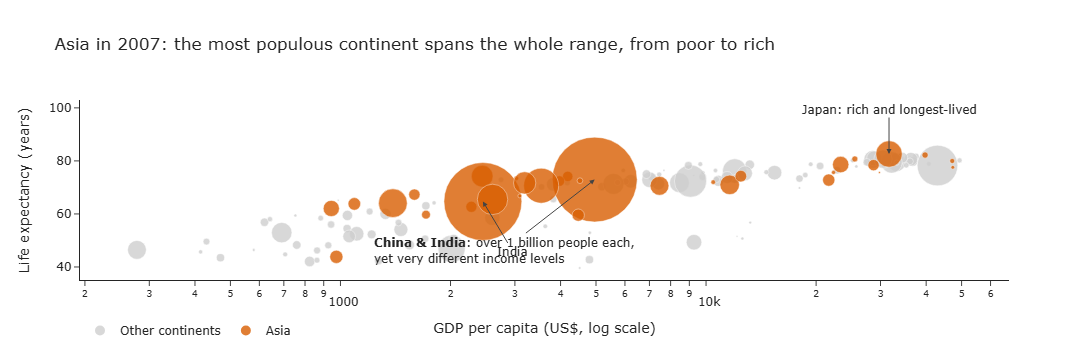

In [4]:
# Task 2 — highlight Asia, grey everything else
d07 = df[df['year'] == 2007].copy()
highlight = 'Asia'
d07['group'] = np.where(d07['continent'] == highlight, highlight, 'Other continents')
d07 = d07.sort_values('group', ascending=False)  # grey drawn first, highlight on top

fig2 = px.scatter(
    d07,
    x='gdpPercap',
    y='lifeExp',
    size='pop',
    size_max=60,
    color='group',
    color_discrete_map={highlight: '#d95f02', 'Other continents': '#cfcfcf'},
    category_orders={'group': ['Other continents', highlight]},
    hover_name='country',
    log_x=True,
    labels={'gdpPercap': 'GDP per capita (US$, log scale)',
            'lifeExp': 'Life expectancy (years)',
            'pop': 'Population',
            'group': ''},
    title='Asia in 2007: the most populous continent spans the whole range, from poor to rich',
)
fig2.update_traces(marker=dict(line=dict(width=0.5, color='white'), opacity=0.8))

# Annotations (x on a log axis must be given as log10 of the value)
def note(country, text, ax, ay):
    r = d07[d07['country'] == country].iloc[0]
    fig2.add_annotation(x=np.log10(r['gdpPercap']), y=r['lifeExp'], text=text,
                        showarrow=True, arrowhead=2, ax=ax, ay=ay,
                        font=dict(size=12), align='left')

note('China', '<b>China & India</b>: over 1 billion people each,<br>yet very different income levels', -90, 70)
note('India', 'India', 30, 50)
note('Japan', 'Japan: rich and longest-lived', 0, -45)

fig2.update_layout(template='simple_white', legend=dict(orientation='h', y=-0.2))
fig2.show()